# 05. Покращення моделей і діагностика

1. **Діагностика**: перевіряємо, чому на test гірше, ніж на val (різниця яскравості знімків, Grad-CAM, приклади помилок).
2. **Нові рецепти навчання** ResNet18: сильніша аугментація, CLAHE (вирівнювання контрасту), нормалізація яскравості кожного знімка, глибший fine-tuning, label smoothing.
3. **Ансамбль**: усереднення ймовірностей кількох моделей.
4. **ROC-криві** й підсумкова таблиця.

Модель, епоху й склад ансамблю вибираємо лише за **val**. Test використовуємо тільки для фінальної оцінки.

### Підготовка: імпорти і дані

Підключаємо бібліотеки. Спільні функції (завантаження даних, датасет, навчання, Grad-CAM, CLAHE, метрики) зібрані у `common_tf.py` і імпортуються звідти. `load_data()` повертає таблицю розбиття, знімки 224 × 224, маски train/val/test і мітки: ті самі, що в notebook 04.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import balanced_accuracy_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay

from common_tf import * 

df, X, tr, va, te, y = load_data()
print("Пристрій:", device, "| знімки:", X.shape, "| train:", tr.sum(), "| val:", va.sum(), "| test:", te.sum())

Пристрій: cpu | знімки: (5856, 224, 224) | train: 4160 | val: 1072 | test: 624


## Частина 1. Діагностика: чому test гірший за val?

**Гіпотеза:** знімки з різних частин датасету відрізняються за технічними характеристиками (яскравість, контраст), і мережа частково вчиться на цьому, а не на легенях. Перевіряємо двома способами.

### 1.1. Яскравість і контраст по частинах датасету
Рядки це оригінальні папки (`train`, `val`, `test`) і клас. Якщо середня яскравість чи контраст помітно різняться між `train` і `test` для одного й того самого класу, це ознака зсуву даних.

In [ ]:
flat = X.reshape(len(X), -1).astype(np.float32)
df["brightness"] = flat.mean(axis=1) 
df["contrast"] = flat.std(axis=1)

df.groupby(["split", "label"])[["brightness", "contrast"]].mean().round(1)

brightness   contrast
split label                           
test  NORMAL     124.099998  59.900002
      PNEUMONIA  119.199997  55.700001
train NORMAL     122.400002  61.200001
      PNEUMONIA  123.199997  55.099998
val   NORMAL     123.800003  64.400002
      PNEUMONIA  126.099998  58.799999

Яскравість і контраст між частинами датасету відрізняються небагато (яскравість 119-126, контраст 55-64), але є цікава деталь: у train і val хворі знімки яскравіші за здорові (123,2 проти 122,4 і 126,1 проти 123,8), а в test навпаки, темніші (119,2 проти 124,1). Контраст у хворих нижчий в усіх трьох частинах. Тобто між train і test зв'язок яскравості з діагнозом змінюється, що може частково пояснювати розрив між val і test.

### 1.2. Контрольний експеримент: діагноз лише за яскравістю
Навчаємо найпростіший класифікатор, який бачить тільки два числа: яскравість і контраст знімка. Balanced accuracy = 0,5 означає вгадування.

- Якщо вона помітно вища за 0,5 на val, а на test близька до 0,5, значить, у train/val яскравість підказує діагноз, а в test уже ні. Це прямий доказ побічної ознаки (shortcut).
- Якщо на обох близько 0,5, яскравість не винна, і причину треба шукати деінде.

In [3]:
feats = df[["brightness", "contrast"]].values
clf = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced"))
clf.fit(feats[tr], y[tr])

for name, mask in [("train", tr), ("val", va), ("test", te)]:
    pred = clf.predict(feats[mask])
    print(f"{name:5s}: balanced accuracy за яскравістю і контрастом = {balanced_accuracy_score(y[mask], pred):.3f}")

train: balanced accuracy за яскравістю і контрастом = 0.662
val  : balanced accuracy за яскравістю і контрастом = 0.703
test : balanced accuracy за яскравістю і контрастом = 0.634


Balanced accuracy за двома числами значно вища за 0,5 в усіх частинах: 0,662 (train), 0,703 (val) і 0,634 (test). Отже, яскравість і контраст самі по собі містять підказку про діагноз, і нейромережа теоретично може на неї спиратись. На test підказка слабша, ніж на val (0,634 проти 0,703), що узгоджується з гіпотезою, але повністю розрив між val і test цим не пояснюється.

### 1.3. Що бачить найкраща модель: Grad-CAM і приклади помилок
**Grad-CAM** малює теплову карту: червоні ділянки сильніше вплинули на відповідь моделі. Для здорових легень без патології ми очікуємо, що модель дивиться на легені, а не на краї знімка, написи чи мітки.

Беремо ResNet18 з fine-tuning із notebook 04. Перша комірка перевіряє, що ваги завантажились правильно: метрики мають збігтися з тими, що були в notebook 04 (accuracy ≈ 0,897).

In [ ]:
model = load_trained("resnet18", RESULTS_DIR / "resnet18_finetune.pth")
test_probs, test_y = get_probs(model, X, y, te)
idx_te = np.where(te)[0]               

print({k: round(v, 3) for k, v in compute_metrics(test_y, test_probs).items()})

{'accuracy': 0.897, 'precision': 0.861, 'recall': 0.997, 'specificity': 0.731, 'f1': 0.924, 'auc': np.float64(0.971)}


Метрики збіглись з notebook 04 (accuracy 0,897, recall 0,997, specificity 0,731), тож ваги завантажились правильно.

Ця комірка малює Grad-CAM для трьох груп знімків із test: **хибні тривоги** (здорові, названі пневмонією), **правильно впізнані здорові** і **правильно впізнані хворі**. З кожної групи беремо по 6 знімків, у яких модель найвпевненіша (у хибних тривог це найбільша ймовірність пневмонії). Верхній рядок: сам знімок і ймовірність, нижній: той самий знімок з тепловою картою, обчисленою за останнім блоком `layer4`.

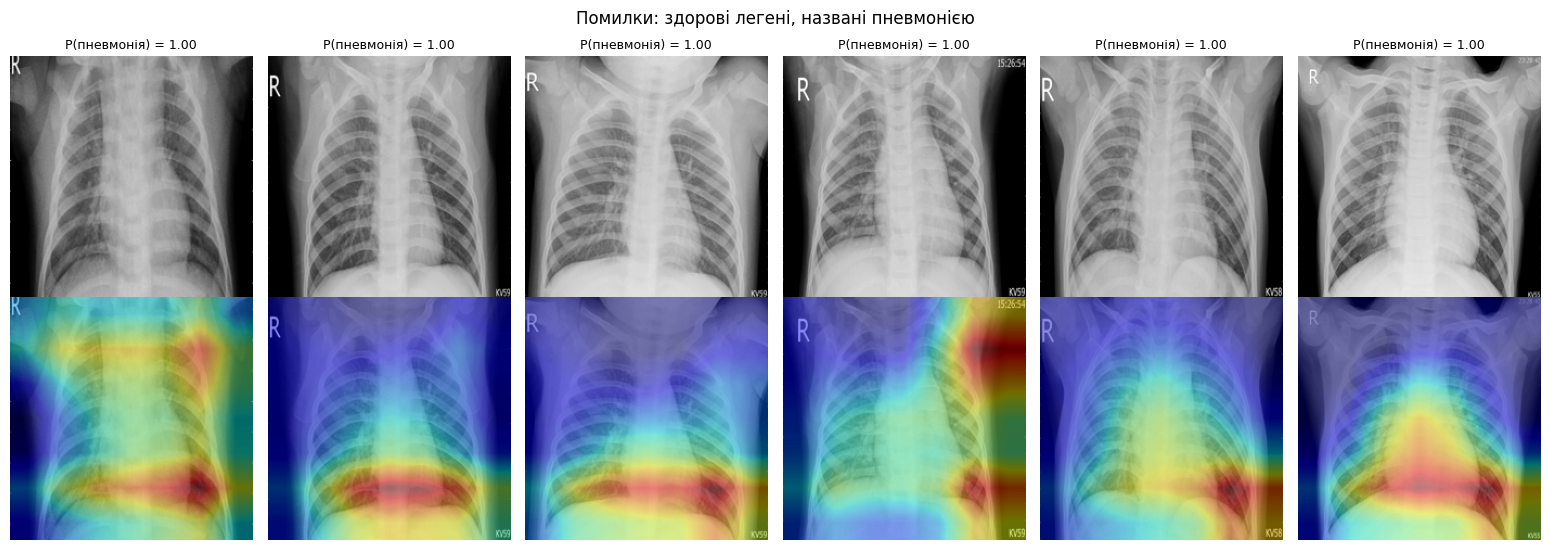

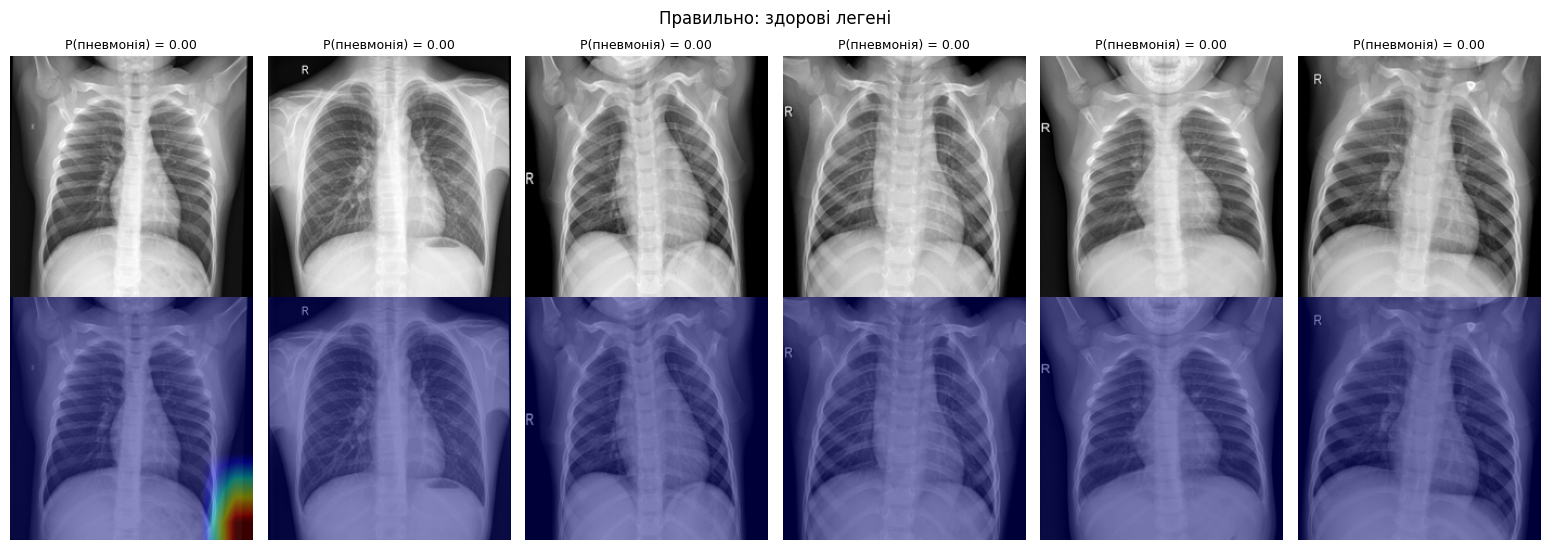

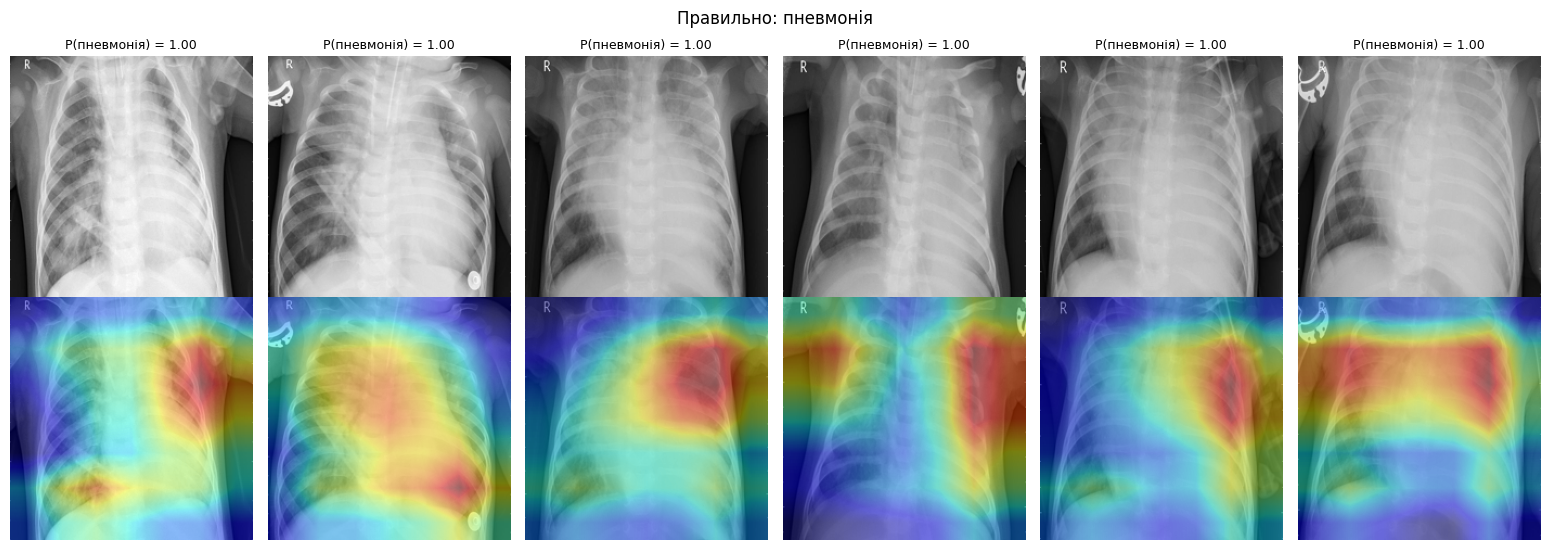

In [ ]:
def show_cam_grid(indices, title, filename, n=6):
    n = min(n, len(indices))
    fig, axes = plt.subplots(2, n, figsize=(2.6 * n, 5.6))
    for k, i in enumerate(indices[:n]):
        x = XrayDS(X[i:i + 1], y[i:i + 1])[0][0].unsqueeze(0)
        cam, p = grad_cam(model, x, model.layer4)
        axes[0, k].imshow(X[i], cmap="gray")
        axes[0, k].set_title(f"P(пневмонія) = {p:.2f}", fontsize=9)
        axes[1, k].imshow(X[i], cmap="gray")
        axes[1, k].imshow(cam, cmap="jet", alpha=0.45)
        for ax in axes[:, k]:
            ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / filename, dpi=150)
    plt.show()


is_fp = (test_y == 0) & (test_probs >= 0.5)
is_tn = (test_y == 0) & (test_probs < 0.5)
is_tp = (test_y == 1) & (test_probs >= 0.5)

fp_idx = idx_te[is_fp][np.argsort(-test_probs[is_fp])]
tn_idx = idx_te[is_tn][np.argsort(test_probs[is_tn])]
tp_idx = idx_te[is_tp][np.argsort(-test_probs[is_tp])]

show_cam_grid(fp_idx, "Помилки: здорові легені, названі пневмонією", "gradcam_false_positive.png")
show_cam_grid(tn_idx, "Правильно: здорові легені", "gradcam_true_negative.png")
show_cam_grid(tp_idx, "Правильно: пневмонія", "gradcam_true_positive.png")

- Якщо червоні ділянки лежать у ділянці легень, модель дивиться туди, куди треба, і помилки це справжні складні випадки.
- Якщо червоне зосереджене на краях, у кутах, на написах чи мітках або поза грудною кліткою, модель покладається на побічні ознаки, і це пояснює розрив між val і test.

## Частина 2. Нові рецепти навчання

Усі три рецепти це ResNet18 з вагами ImageNet, **сильна аугментація** (випадкове кадрування, зсув/поворот, яскравість і контраст ±40%) і ваги класів. Вони відрізняються тим, що саме додано:

| Рецепт | Розморожено | Дані | Додатково |
|---|---|---|---|
| `r18_strongaug` | `layer4` | звичайні | лише сильніша аугментація (як у notebook 04, але сильніша) |
| `r18_clahe` | `layer3` + `layer4` | CLAHE | label smoothing 0,1 |
| `r18_pernorm` | `layer3` + `layer4` | звичайні | нормалізація яскравості кожного знімка, label smoothing 0,1 |

- **CLAHE** локально вирівнює контраст і зменшує різницю в яскравості між знімками.
- **Нормалізація яскравості кожного знімка** приводить кожен знімок до однакових середнього і розкиду.
- **Label smoothing** замість міток 0 і 1 використовує 0,05 і 0,95, що робить мережу менш самовпевненою й зменшує перенавчання.
- Також додано косинусне зниження learning rate.

### 2.1. CLAHE для всіх знімків

Один раз застосовуємо CLAHE до всіх 5 856 знімків і зберігаємо результат у `X_clahe`, щоб не рахувати його щоразу під час навчання. Перевіряємо, що розмір і тип не змінились (224 × 224, `uint8`, значення 0-255).

In [ ]:
X_clahe = make_clahe(X)
print(X_clahe.shape, X_clahe.dtype, X_clahe.min(), X_clahe.max())

CLAHE: 100%|██████████| 5856/5856 [00:18<00:00, 310.26it/s]


(5856, 224, 224) uint8 0 255


### 2.2. Навчання трьох рецептів

У словнику `recipes` для кожного рецепта задано: які дані брати (звичайні чи CLAHE), скільки блоків розморожувати (`last1` це `layer4`, `last2` це `layer3` і `layer4`), чи нормалізувати яскравість кожного знімка і який label smoothing. Сильна аугментація (`strong_aug=True`) увімкнена в усіх. Навчання максимум 10 епох з ранньою зупинкою за val F1 (терпіння 4). 

In [7]:
recipes = {
    "r18_strongaug": dict(X=X,       unfreeze="last1", per_image_norm=False, label_smoothing=0.0),
    "r18_clahe":     dict(X=X_clahe, unfreeze="last2", per_image_norm=False, label_smoothing=0.1),
    "r18_pernorm":   dict(X=X,       unfreeze="last2", per_image_norm=True,  label_smoothing=0.1),
}

labels = {
    "r18_strongaug": "ResNet18 ft + сильна аугментація",
    "r18_clahe":     "ResNet18 ft + CLAHE + layer3",
    "r18_pernorm":   "ResNet18 ft + норм. яскравості + layer3",
}

new_results = {}
for name, cfg in recipes.items():
    new_results[name] = run_experiment(
        name, "resnet18", cfg["unfreeze"], cfg["X"], y, tr, va, te,
        strong_aug=True, per_image_norm=cfg["per_image_norm"],
        label_smoothing=cfg["label_smoothing"], epochs=10, patience=4,
    )

[r18_strongaug] епоха  1 | train 0.0951 | val loss 0.1635 | val F1 0.9656 | 78 с
[r18_strongaug] епоха  2 | train 0.0588 | val loss 0.0962 | val F1 0.9759 | 81 с
[r18_strongaug] епоха  3 | train 0.0470 | val loss 0.0723 | val F1 0.9843 | 82 с
[r18_strongaug] епоха  4 | train 0.0409 | val loss 0.0949 | val F1 0.9804 | 92 с
[r18_strongaug] епоха  5 | train 0.0361 | val loss 0.0907 | val F1 0.9797 | 101 с
[r18_strongaug] епоха  6 | train 0.0280 | val loss 0.0990 | val F1 0.9784 | 107 с
[r18_strongaug] епоха  7 | train 0.0275 | val loss 0.0675 | val F1 0.9849 | 99 с
[r18_strongaug] епоха  8 | train 0.0206 | val loss 0.0736 | val F1 0.9829 | 102 с
[r18_strongaug] епоха  9 | train 0.0230 | val loss 0.0701 | val F1 0.9842 | 96 с
[r18_strongaug] епоха 10 | train 0.0216 | val loss 0.0650 | val F1 0.9849 | 90 с
[r18_clahe] епоха  1 | train 0.2058 | val loss 0.3896 | val F1 0.9006 | 108 с
[r18_clahe] епоха  2 | train 0.1745 | val loss 0.2181 | val F1 0.9638 | 106 с
[r18_clahe] епоха  3 | train 0.

### 2.3. Результати рецептів

Для кожного рецепта виводимо епоху з найкращим val F1 і збираємо метрики на val і test у таблицю `metrics_new`.

In [8]:
rows = []
for key, r in new_results.items():
    print(f"{labels[key]}: найкраща епоха за val = {r['best_epoch']}")
    for split in ["val", "test"]:
        rows.append({"model": labels[key], "split": split, **r[split]})

metrics_new = pd.DataFrame(rows)
metrics_new.round(3)

ResNet18 ft + сильна аугментація: найкраща епоха за val = 7
ResNet18 ft + CLAHE + layer3: найкраща епоха за val = 5
ResNet18 ft + норм. яскравості + layer3: найкраща епоха за val = 5


,model,split,accuracy,precision,recall,specificity,f1,auc
0,ResNet18 ft + сильна аугментація,val,0.978,0.995,0.975,0.985,0.985,0.997
1,ResNet18 ft + сильна аугментація,test,0.918,0.891,0.990,0.799,0.938,0.981
2,ResNet18 ft + CLAHE + layer3,val,0.973,0.996,0.968,0.989,0.982,0.998
3,ResNet18 ft + CLAHE + layer3,test,0.923,0.896,0.992,0.808,0.942,0.973
4,ResNet18 ft + норм. яскравості + layer3,val,0.982,0.996,0.980,0.989,0.988,0.997
5,ResNet18 ft + норм. яскравості + layer3,test,0.913,0.885,0.990,0.786,0.935,0.976


Усі три рецепти покращили test порівняно з ResNet18 з notebook 04 (accuracy 0,897, specificity 0,731): сильна аугментація 0,918 / 0,799, CLAHE + `layer3` 0,923 / 0,808, нормалізація яскравості + `layer3` 0,913 / 0,786. Recall залишився високим (0,990-0,992). На val усі рецепти майже однакові (F1 0,982-0,988), тому вибрати найкращий за val неможливо, а різниця на test між рецептами (0,913-0,923) мала.

### EfficientNet-B0 з тим самим підходом. 

In [ ]:
labels["effnet_clahe"] = "EfficientNet-B0 ft + CLAHE"
recipes["effnet_clahe"] = dict(X=X_clahe, unfreeze="last1", per_image_norm=False, label_smoothing=0.1)
new_results["effnet_clahe"] = run_experiment(
    "effnet_clahe", "efficientnet_b0", "last1", X_clahe, y, tr, va, te,
    strong_aug=True, label_smoothing=0.1, epochs=8, patience=3,
)
rows = [{"model": labels["effnet_clahe"], "split": s, **new_results["effnet_clahe"][s]} for s in ["val", "test"]]
metrics_new = pd.concat([metrics_new, pd.DataFrame(rows)], ignore_index=True)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\Адмін/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:03<00:00, 5.46MB/s]


[effnet_clahe] епоха  1 | train 0.2290 | val loss 0.3064 | val F1 0.9289 | 63 с
[effnet_clahe] епоха  2 | train 0.1949 | val loss 0.3344 | val F1 0.9194 | 66 с
[effnet_clahe] епоха  3 | train 0.1861 | val loss 0.3496 | val F1 0.9088 | 66 с
[effnet_clahe] епоха  4 | train 0.1794 | val loss 0.2788 | val F1 0.9336 | 67 с
[effnet_clahe] епоха  5 | train 0.1796 | val loss 0.2766 | val F1 0.9329 | 70 с
[effnet_clahe] епоха  6 | train 0.1778 | val loss 0.2456 | val F1 0.9415 | 72 с
[effnet_clahe] епоха  7 | train 0.1749 | val loss 0.2486 | val F1 0.9428 | 72 с
[effnet_clahe] епоха  8 | train 0.1767 | val loss 0.2548 | val F1 0.9413 | 72 с


EfficientNet-B0 гірша за ResNet18: на val F1 лише 0,943, а на test вона пропускає 26 хворих (recall 0,933), хоча specificity найвища серед нових моделей (0,816). Через низький val F1 вона в ансамбль не потрапила.

## Частина 3. Ансамбль

Ансамбль це усереднення ймовірностей кількох моделей. Помилки різних моделей часто різні, тому усереднення зазвичай трохи покращує результат і робить його стабільнішим.

- Збираємо передбачення всіх моделей: трьох із notebook 04 (беремо збережені ваги) і нових.
- У ансамбль беремо 3 найкращі моделі за val F1. Вибір за val, а не за test, щоб не було підгонки.
- Для порівняння рахуємо й ансамбль із трьох моделей notebook 04.

### 3.1. Передбачення всіх моделей і вибір трьох найкращих

Збираємо ймовірності на val і test від усіх моделей: трьох збережених з notebook 04 (завантажуємо ваги з `.pth`) і нових з цього notebook. Рахуємо val F1 кожної моделі, сортуємо і вибираємо три найкращі, які й увійдуть в ансамбль. Вибір тільки за val, test не використовується.

In [ ]:
saved = [ 
    ("ResNet18, заморожена",     "resnet18",    "resnet18_frozen",      False, X),
    ("ResNet18, fine-tuning",    "resnet18",    "resnet18_finetune",    False, X),
    ("DenseNet121, fine-tuning", "densenet121", "densenet121_finetune", False, X),
]

pool = {}
for label, arch, fname, pin, data in saved:
    m = load_trained(arch, RESULTS_DIR / f"{fname}.pth")
    vp, _ = get_probs(m, data, y, va, pin)
    tp, _ = get_probs(m, data, y, te, pin)
    pool[label] = {"val_probs": vp, "test_probs": tp}
    del m

for key, r in new_results.items():
    pool[labels[key]] = {"val_probs": r["val_probs"], "test_probs": r["test_probs"]}

val_f1 = {k: f1_score(y[va], (v["val_probs"] >= 0.5).astype(int)) for k, v in pool.items()}
print("Val F1 усіх моделей:")
for k, v in sorted(val_f1.items(), key=lambda kv: -kv[1]):
    print(f"  {v:.4f}  {k}")

top3 = sorted(val_f1, key=val_f1.get, reverse=True)[:3]
print("\nУ ансамбль входять:", top3)

Val F1 усіх моделей:
  0.9893  ResNet18, fine-tuning
  0.9881  ResNet18 ft + норм. яскравості + layer3
  0.9849  ResNet18 ft + сильна аугментація
  0.9843  DenseNet121, fine-tuning
  0.9817  ResNet18 ft + CLAHE + layer3
  0.9500  ResNet18, заморожена
  0.9428  EfficientNet-B0 ft + CLAHE

У ансамбль входять: ['ResNet18, fine-tuning', 'ResNet18 ft + норм. яскравості + layer3', 'ResNet18 ft + сильна аугментація']


Найкращі за val F1: `ResNet18, fine-tuning` (0,989), `ResNet18 ft + норм. яскравості + layer3` (0,988) і `ResNet18 ft + сильна аугментація` (0,985). EfficientNet і заморожена ResNet18 помітно слабші.

### 3.2. Ансамбль і його метрики

Функція `ensemble` усереднює ймовірності вибраних моделей (окремо для val і test). Рахуємо два ансамблі: з трьох найкращих за val F1 і з трьох моделей notebook 04. Другий потрібен для порівняння: він показує, чи дають щось нові рецепти порівняно зі старими моделями.

In [11]:
def ensemble(names):
    return (np.mean([pool[k]["val_probs"] for k in names], axis=0),
            np.mean([pool[k]["test_probs"] for k in names], axis=0))

ens_sets = {
    "Ансамбль (топ-3 за val F1)": top3,
    "Ансамбль (3 моделі з ноутбука 04)": [l for l, *_ in saved],
}

ens_rows, ens_probs = [], {}
for ens_name, members in ens_sets.items():
    ev, et = ensemble(members)
    ens_probs[ens_name] = et
    ens_rows.append({"model": ens_name, "split": "val", **compute_metrics(y[va], ev)})
    ens_rows.append({"model": ens_name, "split": "test", **compute_metrics(y[te], et)})

metrics_ens = pd.DataFrame(ens_rows)
metrics_ens.round(3)

,model,split,accuracy,precision,recall,specificity,f1,auc
0,Ансамбль (топ-3 за val F1),val,0.982,0.995,0.981,0.985,0.988,0.998
1,Ансамбль (топ-3 за val F1),test,0.917,0.884,0.997,0.782,0.937,0.977
2,Ансамбль (3 моделі з ноутбука 04),val,0.979,0.997,0.975,0.993,0.986,0.998
3,Ансамбль (3 моделі з ноутбука 04),test,0.899,0.863,0.997,0.735,0.925,0.971


Ансамбль топ-3 на test: accuracy 0,917, recall 0,997, specificity 0,782, AUC 0,977. Він кращий за ансамбль із моделей notebook 04 (0,899 і 0,735). Проте він не перевершує найкращих окремих моделей (CLAHE + `layer3` має accuracy 0,923), а лише зрівнюється з найкращим учасником (`сильна аугментація`, 0,918). Перевага ансамблю в тому, що він майже не пропускає хворих.

## Частина 4. ROC-криві та матриця помилок найкращого ансамблю

ROC-крива показує компроміс між recall і specificity при усіх порогах одразу, а AUC це площа під нею (1,0 ідеально, 0,5 вгадування). Це оцінка того, наскільки добре модель взагалі розрізняє класи, незалежно від порога 0,5.

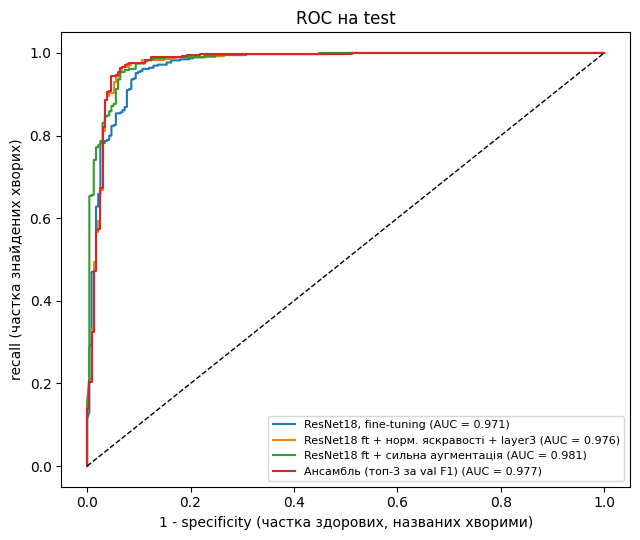

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
curves = {k: pool[k]["test_probs"] for k in top3}
curves["Ансамбль (топ-3 за val F1)"] = ens_probs["Ансамбль (топ-3 за val F1)"]
for k, p in curves.items():
    fpr, tpr, _ = roc_curve(y[te], p)
    ax.plot(fpr, tpr, label=f"{k} (AUC = {roc_auc_score(y[te], p):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("1 - specificity (частка здорових, названих хворими)")
ax.set_ylabel("recall (частка знайдених хворих)")
ax.set_title("ROC на test")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "roc_test.png", dpi=150)
plt.show()

AUC усіх моделей на test високий (0,971-0,981), хоча specificity лише 0,73-0,80. Тобто мережі непогано розрізняють класи за ймовірностями, але при порозі 0,5 багато здорових знімків все одно отримують високу ймовірність пневмонії. Але підбирати поріг за test не можна.

### 4.2. Матриця помилок ансамблю

Матриця помилок на test для ансамблю «топ-3 за val F1». Показує, скільки здорових помилково названо хворими і скільки хворих пропущено.

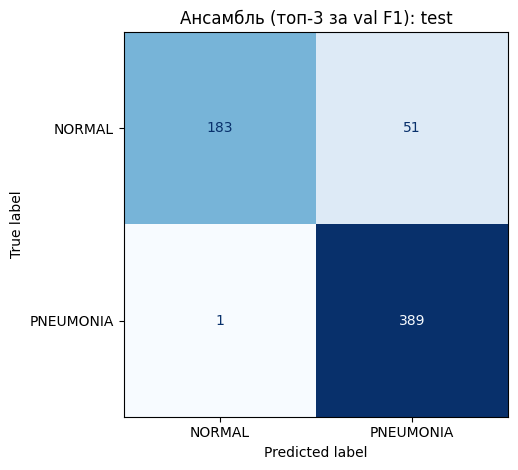

In [13]:
best_ens = "Ансамбль (топ-3 за val F1)"
pred = (ens_probs[best_ens] >= 0.5).astype(int)
cm = confusion_matrix(y[te], pred)
ConfusionMatrixDisplay(cm, display_labels=["NORMAL", "PNEUMONIA"]).plot(cmap="Blues", colorbar=False)
plt.title(best_ens + ": test")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "cm_ensemble.png", dpi=150)
plt.show()

Ансамбль на test пропускає 1 хворого з 390 і хибно позначає пневмонією 51 здорового з 234.

## Частина 5. Збереження результатів

Об'єднуємо нові метрики з тими, що були раніше, і зберігаємо у `results/final_metrics_all.csv`.

In [14]:
improved = pd.concat([metrics_new, metrics_ens], ignore_index=True)
improved.to_csv(RESULTS_DIR / "metrics_improved.csv", index=False)

old = pd.read_csv(RESULTS_DIR / "final_metrics.csv")
all_metrics = pd.concat([old, improved], ignore_index=True)
all_metrics.to_csv(RESULTS_DIR / "final_metrics_all.csv", index=False)

(all_metrics[all_metrics["split"] == "test"]
    .drop(columns="split")
    .sort_values("accuracy", ascending=False)
    .round(3))

,model,accuracy,precision,recall,specificity,f1,auc
23,ResNet18 ft + CLAHE + layer3,0.923,0.896,0.992,0.808,0.942,0.973
21,ResNet18 ft + сильна аугментація,0.918,0.891,0.990,0.799,0.938,0.981
29,Ансамбль (топ-3 за val F1),0.917,0.884,0.997,0.782,0.937,0.977
25,ResNet18 ft + норм. яскравості + layer3,0.913,0.885,0.990,0.786,0.935,0.976
31,Ансамбль (3 моделі з ноутбука 04),0.899,0.863,0.997,0.735,0.925,0.971
17,"ResNet18, fine-tuning",0.897,0.861,0.997,0.731,0.924,0.971
27,EfficientNet-B0 ft + CLAHE,0.889,0.894,0.933,0.816,0.913,0.960
15,"ResNet18, заморожена",0.872,0.857,0.954,0.735,0.903,0.951
19,"DenseNet121, fine-tuning",0.862,0.823,0.992,0.645,0.900,0.966
13,CNN + аугментація + ваги,0.804,0.767,0.987,0.500,0.863,NaN


Файл `final_metrics_all.csv` містить метрики всіх моделей. На чолі таблиці за test accuracy стоять моделі з цього notebook: CLAHE + `layer3` (0,923), сильна аугментація (0,918) і ансамбль (0,917).

## Частина 6. Стабільність результату: кілька запусків

Один запуск з одним seed може бути «щасливим» або «невдалим», особливо при 234 здорових знімках у test. Повторюємо найкращий новий рецепт (за val F1) із двома іншими seed і дивимось на середнє й розкид.

Якщо розкид між запусками порівнянний з різницею між моделями, значить, ці різниці не варто вважати суттєвими.

In [15]:
best_new = max(new_results, key=lambda k: new_results[k]["val"]["f1"])
cfg = recipes[best_new]
print("Повторюємо рецепт:", labels[best_new])

seed_rows = [{"seed": SEED, **new_results[best_new]["test"]}]
for s in [1, 2]:
    r = run_experiment(
        f"{best_new}_seed{s}", "resnet18", cfg["unfreeze"], cfg["X"], y, tr, va, te,
        strong_aug=True, per_image_norm=cfg["per_image_norm"],
        label_smoothing=cfg["label_smoothing"], epochs=10, patience=4, seed=s, save=False,
    )
    seed_rows.append({"seed": s, **r["test"]})

seeds_df = pd.DataFrame(seed_rows)
display(seeds_df.round(3))
display(seeds_df[["accuracy", "recall", "specificity", "auc"]].agg(["mean", "std"]).round(3))

Повторюємо рецепт: ResNet18 ft + норм. яскравості + layer3
[r18_pernorm_seed1] епоха  1 | train 0.1931 | val loss 0.3565 | val F1 0.9238 | 100 с
[r18_pernorm_seed1] епоха  2 | train 0.1746 | val loss 0.1668 | val F1 0.9706 | 109 с
[r18_pernorm_seed1] епоха  3 | train 0.1634 | val loss 0.1969 | val F1 0.9712 | 121 с
[r18_pernorm_seed1] епоха  4 | train 0.1613 | val loss 0.1847 | val F1 0.9672 | 122 с
[r18_pernorm_seed1] епоха  5 | train 0.1530 | val loss 0.1424 | val F1 0.9875 | 112 с
[r18_pernorm_seed1] епоха  6 | train 0.1507 | val loss 0.1529 | val F1 0.9881 | 109 с
[r18_pernorm_seed1] епоха  7 | train 0.1497 | val loss 0.1642 | val F1 0.9829 | 108 с
[r18_pernorm_seed1] епоха  8 | train 0.1467 | val loss 0.1629 | val F1 0.9790 | 107 с
[r18_pernorm_seed1] епоха  9 | train 0.1467 | val loss 0.1421 | val F1 0.9861 | 107 с
[r18_pernorm_seed1] епоха 10 | train 0.1449 | val loss 0.1491 | val F1 0.9849 | 110 с
Рання зупинка: 4 епох без покращення
[r18_pernorm_seed2] епоха  1 | train 0.1974 

,seed,accuracy,precision,recall,specificity,f1,auc
0,42,0.913,0.885,0.990,0.786,0.935,0.976
1,1,0.933,0.907,0.995,0.829,0.949,0.955
2,2,0.929,0.906,0.990,0.829,0.946,0.969


,accuracy,recall,specificity,auc
mean,0.925,0.991,0.815,0.967
std,0.010,0.003,0.025,0.011


Три запуски одного рецепта дали accuracy 0,913, 0,933 і 0,929 (середнє 0,925, std 0,010), specificity 0,786-0,829 (std 0,025). Розкид між seed (≈ 0,02) порівнянний з різницею між рецептами (0,913-0,923), тому говорити, що один рецепт кращий за інший, не можна. Надійно можна стверджувати лише те, що нові рецепти в середньому трохи кращі за ResNet18 з notebook 04 (0,897).

## Підсумок

**Що зроблено**
- Перевірили гіпотезу про зсув даних: порівняли яскравість і контраст по частинах датасету, навчили класифікатор лише за цими двома числами, побудували Grad-CAM для ResNet18.
- Навчили три нові рецепти ResNet18 (сильна аугментація, CLAHE + `layer3`, нормалізація яскравості + `layer3`) і EfficientNet-B0.
- Зібрали ансамбль із трьох найкращих за val F1 моделей, побудували ROC-криві й матрицю помилок.

**Висновки**
- Яскравість і контраст дають підказку про діагноз (balanced accuracy 0,63-0,70), а на test вона трохи слабша. Це може частково пояснювати розрив між val і test, але не пояснює його повністю.
- Нові рецепти покращили test: accuracy 0,913-0,923 проти 0,897, specificity 0,79-0,81 проти 0,73. Але розкид між seed (≈ 0,02) порівнянний з різницею між рецептами.
- Ансамбль (accuracy 0,917, recall 0,997, 51 хибна тривога і 1 пропуск) кращий за старий ансамбль, але не за найкращу окрему модель.
- AUC високий (0,97-0,98) при specificity 0,78-0,81: мережі розрізняють класи, а проблема в порозі та зсуві даних.
- Обмеження: один датасет, діти 1-5 років, одна лікарня; результати не можна переносити на клінічне використання.